# Fitting the `"duecker"` dipole baseline correction

The `duecker_ET_model` pyramidal cells have an h-current gradient that causes an increasing gradient in resting membrane potential along the apical dendrites. 
This produces a slow drift in the dipole (which is also corrected for in the original `neymotin_2020_model`). 

This notebook characterises that drift and fits a correction that is subtracted when calling `simulate_dipole` with `bsl_cor="duecker"`.

Steps:
1. Simulate the network with no drives (`bsl_cor='none'`) for 1 s.
2. Fit an exponential decay to the L2 and L5 baseline dipoles (the amplitudes
   `A`, `C` are read from the data; only the rate `b` is fit).
3. Save the baseline traces + fit parameters to
   `hnn_core/param/bsl_dipole_dueckerET.json` (this file lives in the hnn-core
   fork and is what `bsl_cor="duecker"` reads).

In [1]:
import os.path as op
import json

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

import hnn_core
from hnn_core import duecker_ET_model, simulate_dipole, neymotin_2020_model, MPIBackend  # noqa: F401 (MPIBackend for the optional MPI run below)

hnn_core_root = op.dirname(hnn_core.__file__)

# The number of cores may need modifying depending on your current machine.
n_procs = 10

## Baseline simulation (no external drives)

In [2]:
tstop = 1000

net_no_drives = duecker_ET_model()
net_no_drives.set_cell_positions(inplane_distance=30.)

# to run in parallel instead:  with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
dpl_net_no_drives = simulate_dipole(net_no_drives, tstop=tstop, n_trials=1,
                                    bsl_cor='none', record_vsec='all')[0]


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/dipole.py:100: UserWarning: No external drives or biases loaded
  warnings.warn("No external drives or biases loaded", UserWarning)


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Trial 1: 250.0 ms...
Trial 1: 260.0 ms...
Trial 1: 270.0 ms...
Trial 1: 280.0 ms...
Trial 1: 290.0 ms...
Trial 1: 300.0 ms...
Trial 1: 310.0 ms...
Trial 1: 320.0 ms...
Trial 1: 330.0 ms...
Trial 1: 340.0 ms...
Trial 1: 350.0 ms...
Tr

## Diagnostic: baseline dipole and settling membrane potentials

This plot shows the gradient in the membrane potential and how it effects the dipole moment.
As the apical tuft is depolarized compared to the soma, the dipole moment is negative.

Text(0.5, 1.0, 'L5 pyramidal neuron')

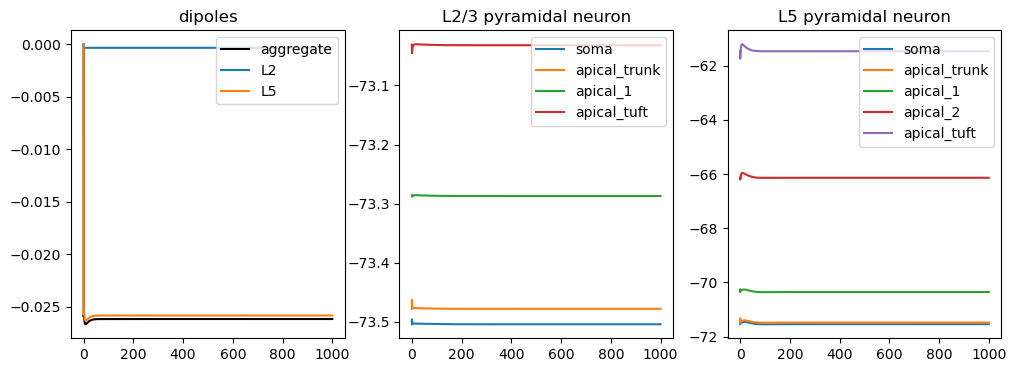

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].plot(dpl_net_no_drives.times, dpl_net_no_drives.data['agg'], linewidth=1.5, color='k', label='aggregate')
ax[0].plot(dpl_net_no_drives.times, dpl_net_no_drives.data['L2'], linewidth=1.5, label='L2')
ax[0].plot(dpl_net_no_drives.times, dpl_net_no_drives.data['L5'], linewidth=1.5, label='L5')
ax[0].set_title('dipoles')
ax[0].legend(loc='upper right')

for section in ['soma', 'apical_trunk', 'apical_1', 'apical_tuft']:
    v_s = net_no_drives.cell_response.vsec[0][35][section]   # gid 35: an L2/3 pyramidal cell
    ax[1].plot(dpl_net_no_drives.times, np.array(v_s), label=section, linewidth=1.5)
ax[1].legend(loc='upper right')
ax[1].set_title('L2/3 pyramidal neuron')

for section in ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']:
    v_s = net_no_drives.cell_response.vsec[0][170][section]  # gid 170: an L5 pyramidal cell
    ax[2].plot(dpl_net_no_drives.times, np.array(v_s), label=section, linewidth=1.5)
ax[2].legend(loc='upper right')
ax[2].set_title('L5 pyramidal neuron')

## Fit the exponential-decay drift and save the correction

In [4]:
# exponential decay function
def exp_decay(t, A, C, b):
    return ((C - A) * np.exp(-b * (t))) + A


# decay wrapper functions
def _exp_decay_wrapper_l2(t, b):
    return exp_decay(t, A_L2, C_L2, b)

def _exp_decay_wrapper_l5(t, b):
    return exp_decay(t, A_L5, C_L5, b)

In [5]:
# baseline dipole
bsl_dipole_ca = {'times': dpl_net_no_drives.times.tolist(),
                 'L2': dpl_net_no_drives.data['L2'].tolist(),
                 'L5': dpl_net_no_drives.data['L5'].tolist()}

# get A and C parameters for curvefit
A_L2 = bsl_dipole_ca['L2'][-1]
A_L5 = bsl_dipole_ca['L5'][-1]

C_L2 = bsl_dipole_ca['L2'][1]
C_L5 = bsl_dipole_ca['L5'][1]

# fit from the second sample to avoid fitting an offset
popt_l2, pcov = curve_fit(_exp_decay_wrapper_l2, bsl_dipole_ca['times'][1:], bsl_dipole_ca['L2'][1:], p0=(0.01), bounds=(0, np.inf))
popt_l5, pcov = curve_fit(_exp_decay_wrapper_l5, bsl_dipole_ca['times'][1:], bsl_dipole_ca['L5'][1:], p0=(0.01), bounds=(0, np.inf))

# get the parameters for the exponential fit
exp_fit_l2 = _exp_decay_wrapper_l2(np.array(bsl_dipole_ca['times']), *popt_l2)
exp_fit_l5 = _exp_decay_wrapper_l5(np.array(bsl_dipole_ca['times']), *popt_l5)

bsl_dipole_ca['popt_l2'] = list(popt_l2)
bsl_dipole_ca['popt_l5'] = list(popt_l5)

# store parameters
with open(op.join(hnn_core_root, 'param', 'bsl_dipole_dueckerET.json'), 'w') as f:
    json.dump(bsl_dipole_ca, f, indent=4, ensure_ascii=False)

## Before / after baseline correction

Inspect the result. The baseline correction does not lead to a perfectly straight line, but for a scaling factor at the order of ~1000, the fluctuation is 2-4 (smaller than the dipole signal).
This error margin is smaller than for the original `neymotin_2020_model`.

Text(0.5, 1.0, 'Baseline corrected dipoles')

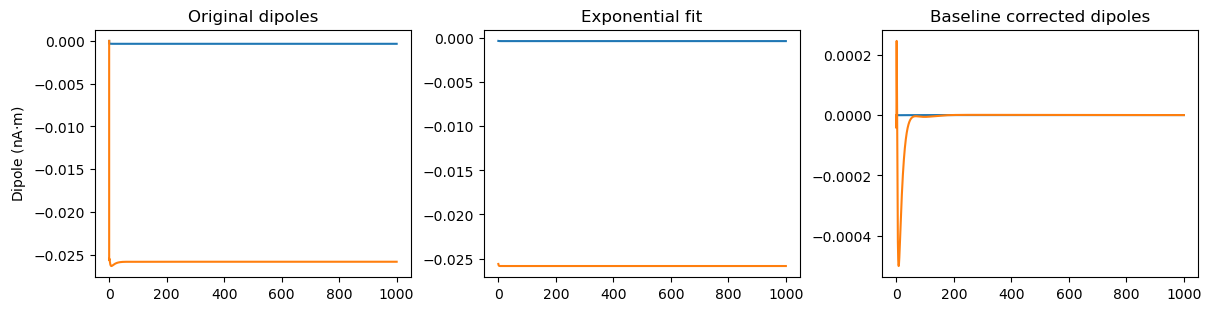

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3), constrained_layout=True)
ax[0].plot(dpl_net_no_drives.times, dpl_net_no_drives.data['L2'])
ax[0].plot(dpl_net_no_drives.times, dpl_net_no_drives.data['L5'])
ax[0].set_title('Original dipoles')
ax[0].set_ylabel(r'Dipole (nA$\cdot$m)')
ax[1].plot(dpl_net_no_drives.times[1:], exp_fit_l2[1:])
ax[1].plot(dpl_net_no_drives.times[1:], exp_fit_l5[1:])
ax[1].set_title('Exponential fit')
dpl_bsl_cor = dpl_net_no_drives.copy()
dpl_bsl_cor.data['L2'][1:] = dpl_net_no_drives.data['L2'][1:] - exp_fit_l2[1:]
dpl_bsl_cor.data['L5'][1:] = dpl_net_no_drives.data['L5'][1:] - exp_fit_l5[1:]
ax[2].plot(dpl_bsl_cor.times, dpl_bsl_cor.data['L2'])
ax[2].plot(dpl_bsl_cor.times, dpl_bsl_cor.data['L5'])
ax[2].set_title('Baseline corrected dipoles')

In [7]:
net_neymo = neymotin_2020_model()
dpl_neymo = simulate_dipole(net_neymo, tstop=1000, bsl_cor="neymotin")[0]

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Trial 1: 250.0 ms...
Trial 1: 260.0 ms...
Trial 1: 270.0 ms...
Trial 1: 280.0 ms...
Trial 1: 290.0 ms...
Trial 1: 300.0 ms...
Trial 1: 310.0 ms...
Trial 1: 320.0 ms...
Trial 1: 330.0 ms...
Trial 1: 340.0 ms...
Trial 1: 350.0 ms...
Trial 1: 360.0 ms...
Trial 1: 370.0 ms...
Trial 1: 380.0 ms...
Trial 1: 390.0 ms...
Trial 1: 400.0 ms...
Trial 1: 410.0 ms...
Trial 1: 420.0 ms...

Text(0.5, 1.0, 'neymotin_2020_model')

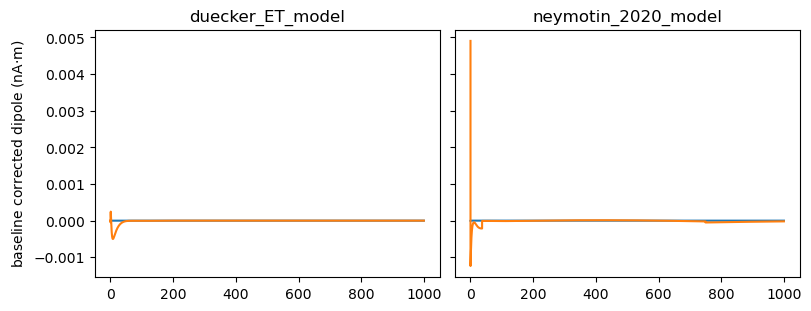

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3), constrained_layout=True, sharey=True)
ax[0].plot(dpl_bsl_cor.times, dpl_bsl_cor.data['L2'])
ax[0].plot(dpl_bsl_cor.times, dpl_bsl_cor.data['L5'])
ax[0].set_ylabel(r'baseline corrected dipole (nA$\cdot$m)')

ax[0].set_title('duecker_ET_model')

ax[1].plot(dpl_neymo.times, dpl_neymo.data['L2'])
ax[1].plot(dpl_neymo.times, dpl_neymo.data['L5'])
ax[1].set_title('neymotin_2020_model')